# EDA 3 · Time series

Daily series per game (reviews, 👍 share, review types, online players), their trend, weekly seasonality, stationarity and autocorrelation, and unusual days such as review bombing.

In [1]:
import textwrap
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss

from src.config import FEATURES_DIR, TOPIC_NOISE, TOPIC_SHORT, game_names
from src.db import read
from src.features.anomalies import KINDS, group_events, platform_days, review_anomalies
from src.features.daily import (
    collection, daily_series, daily_topics, launch_window, online_players, patch_days, weekly,
)
from src.text.topics import topic_names
from src.viz.charts import LANG_COLORS, PATCH_COLOR, date_axis, per_game_panels, use_style

use_style()
warnings.filterwarnings("ignore", category=InterpolationWarning)  # KPSS p outside its table: shown as 0.01 or 0.1
KIND_COLORS = {"bombing": "#e34948", "negative": "#eda100", "spike": "#2a78d6"}

In [2]:
MIN_DAILY = 50          # median reviews per day over the last year to analyse a game per day; fewer: per week
RECENT_DAYS = 730       # trend, stationarity and autocorrelation: the last 2 years
LAUNCH_DAYS = 30        # ... without a game's first days (launch spike)
MIN_HISTORY = 60        # ... and only for games with at least this many days left after that
TOP_GAMES = 6           # games in the detailed charts (most reviews)
ANOMALY_WINDOW = 28     # days of history a day is compared to
ANOMALY_WEEKS = 12      # weeks of history a week is compared to (games analysed per week)
ANOMALY_Z = 4.0         # how unusual a day must be (robust standard deviations)
TOP_EVENTS = 15         # rows in the anomaly tables

## 1. The series

One row per game and day from its first review to yesterday. Days without reviews are 0.

In [3]:
names = game_names()
series = daily_series()
topic_counts = daily_topics()
patches = patch_days()
online = online_players()
news = read.news(columns=["appid", "published_at", "title", "is_patch"])
news["day"] = news["published_at"].dt.tz_convert(None)
topic_labels = topic_names(read.topics())

FEATURES_DIR.mkdir(parents=True, exist_ok=True)
series.to_parquet(FEATURES_DIR / "daily.parquet")
topic_counts.rename(columns=str).to_parquet(FEATURES_DIR / "daily_topics.parquet")  # parquet: text column names
print(f"{series.index.get_level_values('appid').nunique()} games, {len(series):,} game-days, "
      f"{series['n'].sum():,} kept reviews, {topic_counts.to_numpy().sum():,} of them with a topic")

62 games, 149,676 game-days, 25,022,355 kept reviews, 25,022,355 of them with a topic


In [4]:
def games_in(df, appids):
    return df[df.index.get_level_values("appid").isin(appids)]


last_day = series.index.get_level_values("day").max()
last_year = series[series.index.get_level_values("day") > last_day - pd.Timedelta(days=365)]
collected = collection()
release = pd.to_datetime(read.games().set_index("appid")["release_date"])
coverage = pd.DataFrame({
    "game": pd.Series(names),
    "first_review": series.index.to_frame(index=False).groupby("appid")["day"].min(),
    "release": release,
    "reviews": series.groupby(level="appid")["n"].sum(),
    "per_day_last_year": last_year.groupby(level="appid")["n"].median(),
    "online_daily_since": online[online["daily"]].groupby("appid")["day"].min(),
    "patches": pd.Series(patches.get_level_values("appid")).value_counts(),
    "steam_coverage": collected["coverage"],
    "complete": collected["complete"],
    "collected_until": collected["collected_at"].dt.tz_convert(None),
}).dropna(subset=["reviews"]).sort_values("reviews", ascending=False)
with pd.option_context("display.max_rows", 200):
    display(coverage.style.format({
        "first_review": "{:%Y-%m-%d}", "release": "{:%Y-%m-%d}", "online_daily_since": "{:%Y-%m-%d}", "collected_until": "{:%Y-%m-%d %H:%M}",
        "reviews": "{:,.0f}", "per_day_last_year": "{:,.0f}", "patches": "{:.0f}", "steam_coverage": "{:.0%}",
    }, na_rep=""))

left_out = coverage[coverage["complete"].eq(False)]
coverage = coverage.drop(left_out.index)  # the analysis below: complete games (or unknown: no Steam count)
series, topic_counts = games_in(series, coverage.index), games_in(topic_counts, coverage.index)
coverage["launch"] = coverage[["first_review", "release"]].max(axis=1)  # e.g. CS:GO: beta in May, release in August


coverage["per"] = np.where(coverage["per_day_last_year"] >= MIN_DAILY, "day", "week")
daily_games = coverage.index[coverage["per"] == "day"]
weekly_games = coverage.index[coverage["per"] == "week"]
top_games = coverage.index[:TOP_GAMES]
top_daily = [a for a in top_games if a in daily_games]
weekly_series = weekly(games_in(series, weekly_games))
print(f"left out, not fully collected: {', '.join(left_out['game']) or 'none'}")
print(f"per day: {len(daily_games)} games, per week: {len(weekly_games)} games "
      f"(fewer than {MIN_DAILY} reviews on a typical day of the last year)")

,game,first_review,release,reviews,per_day_last_year,online_daily_since,patches,steam_coverage,complete,collected_until
730,Counter-Strike 2,2012-05-12,2012-08-21,"6,177,232","1,590",2026-08-09,251,100%,True,2026-11-06 12:32
570,Dota 2,2011-08-01,2013-07-09,"2,270,752",509,2026-08-08,118,100%,True,2026-11-09 14:25
105600,Terraria,2011-05-16,2011-05-16,"1,133,664",235,2026-08-10,5,100%,True,2026-11-07 15:09
553850,Helldivers 2,2024-02-08,2024-02-08,"977,276",177,2026-08-09,89,100%,True,2026-11-06 22:55
440,Team Fortress 2,2010-10-15,2007-10-10,"909,204",160,2026-08-10,139,100%,True,2026-11-07 16:47
1172470,Apex Legends™,2020-11-05,2020-11-04,"807,890",147,2026-08-10,143,100%,True,2026-11-07 04:07
1091500,Cyberpunk 2077,2020-12-10,2020-12-09,"751,305",202,2026-08-10,40,100%,True,2026-11-07 02:41
413150,Stardew Valley,2016-02-26,2016-02-26,"722,882",211,2026-08-10,34,100%,True,2026-11-07 18:41
236390,War Thunder,2013-08-15,2013-08-15,"674,916",240,2026-08-09,374,100%,True,2026-11-06 21:27
1086940,Baldur's Gate 3,2020-10-06,2023-08-03,"663,897",127,2026-08-10,99,100%,True,2026-11-07 01:41


left out, not fully collected: none
per day: 39 games, per week: 23 games (fewer than 50 reviews on a typical day of the last year)


- `steam_coverage`: reviews we have / Steam's count from the latest collection run. `complete`: at least 95% in every language. Both come from the raw pages, so they hold for data collected by anyone (e.g. synced from a coworker).
- Games that are not complete have only their newest reviews, so their series would start too late: they are **left out of everything below** until they are fully collected.
- `collected_until`: start of the oldest of the game's latest runs per language; its series ends the day before.

Reviews per month for every game, ordered by first review. Launches, big updates and slow decline are visible at a glance.

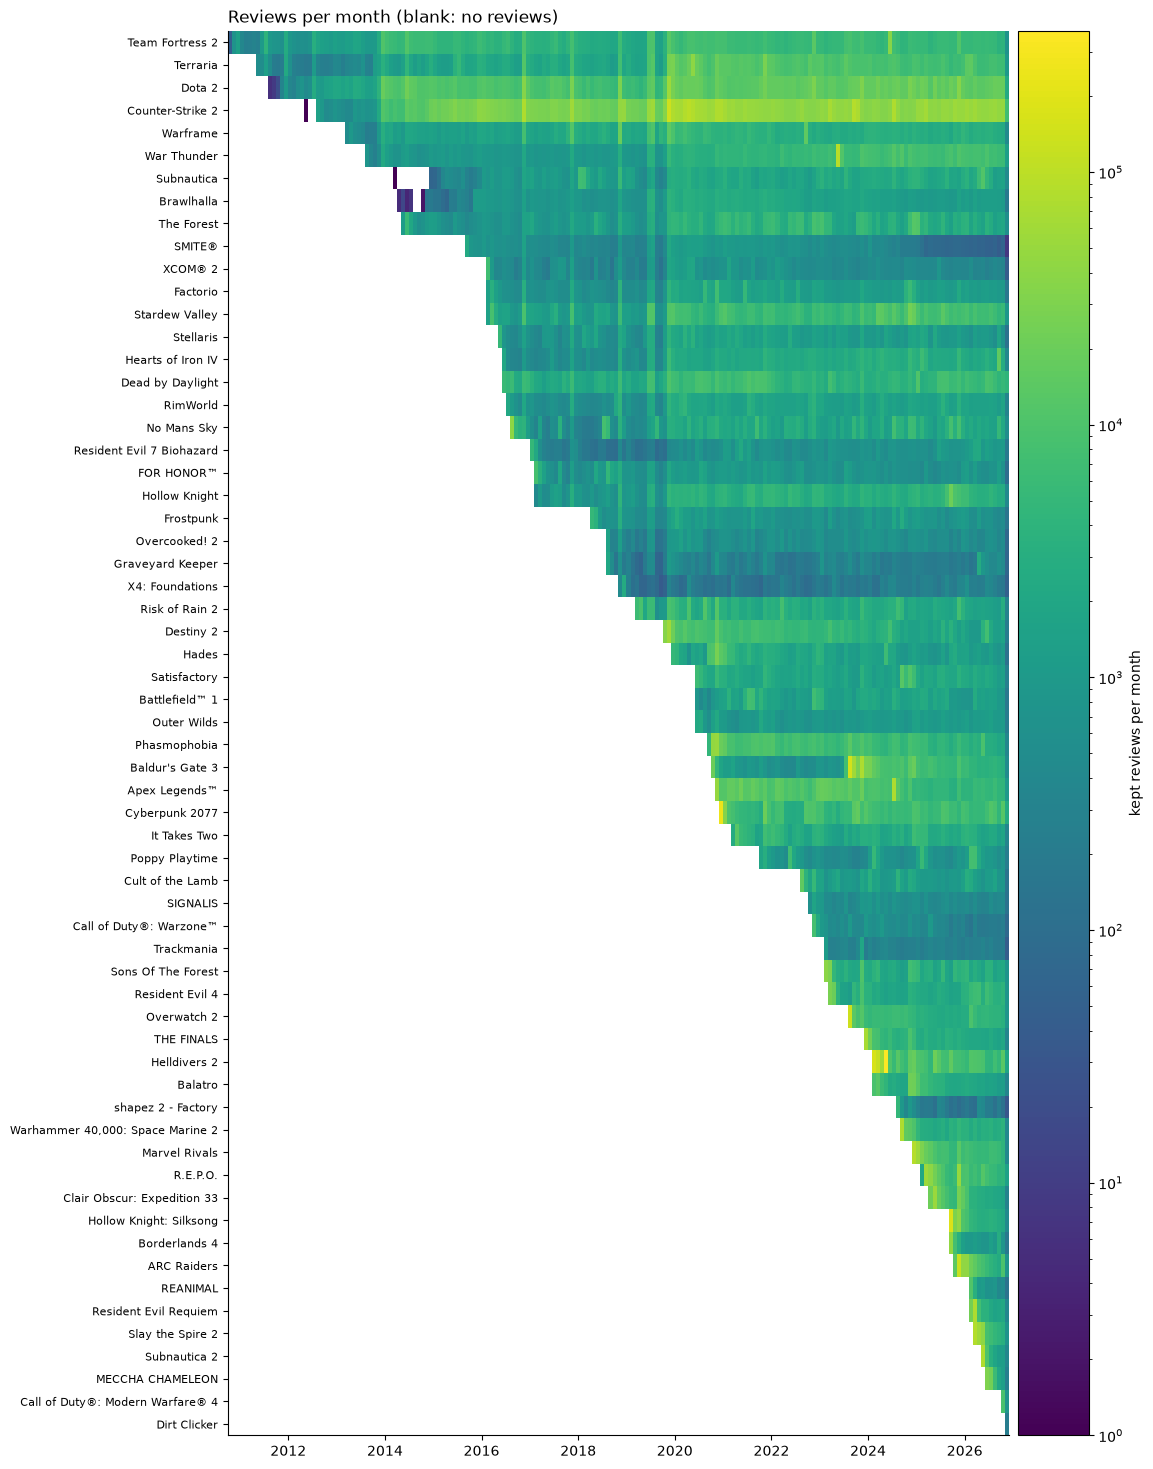

In [5]:
month = series.index.get_level_values("day").to_period("M").to_timestamp()
monthly_n = series["n"].groupby([series.index.get_level_values("appid"), month]).sum().unstack()
monthly_n = monthly_n.loc[coverage.sort_values("first_review").index]
x = mdates.date2num(monthly_n.columns)
fig, ax = plt.subplots(figsize=(12, 0.27 * len(monthly_n) + 1.5))
image = ax.imshow(monthly_n.where(monthly_n > 0), aspect="auto", norm=LogNorm(), cmap="viridis",
                  interpolation="nearest", extent=[x[0], x[-1] + 31, len(monthly_n) - 0.5, -0.5])
ax.xaxis_date()
date_axis(ax)
ax.set_yticks(range(len(monthly_n)), monthly_n.index.map(names), fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, label="kept reviews per month", pad=0.01)
ax.set_title("Reviews per month (blank: no reviews)", loc="left");

**Every game over time**: reviews and 👍 share per week (complete weeks; the 👍 share only for weeks with at least 20 reviews), with patch days.

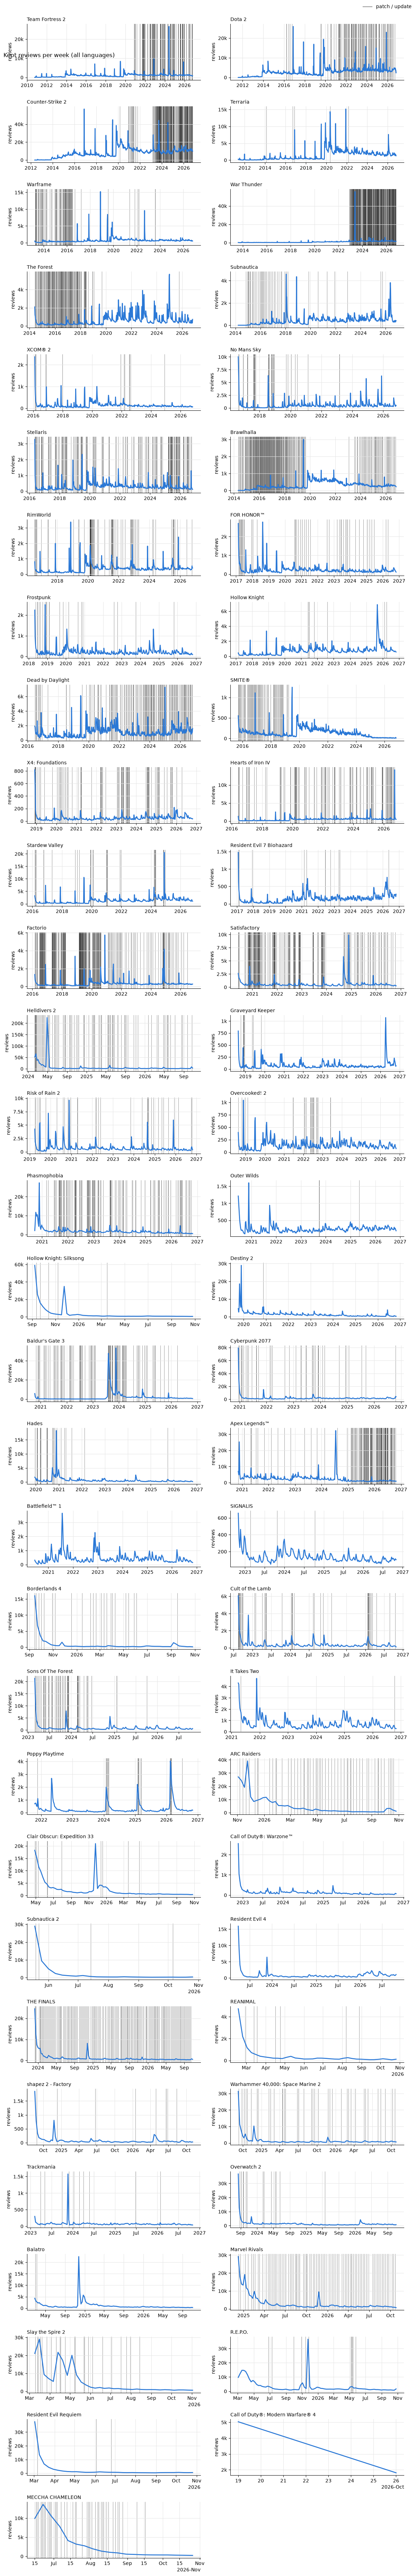

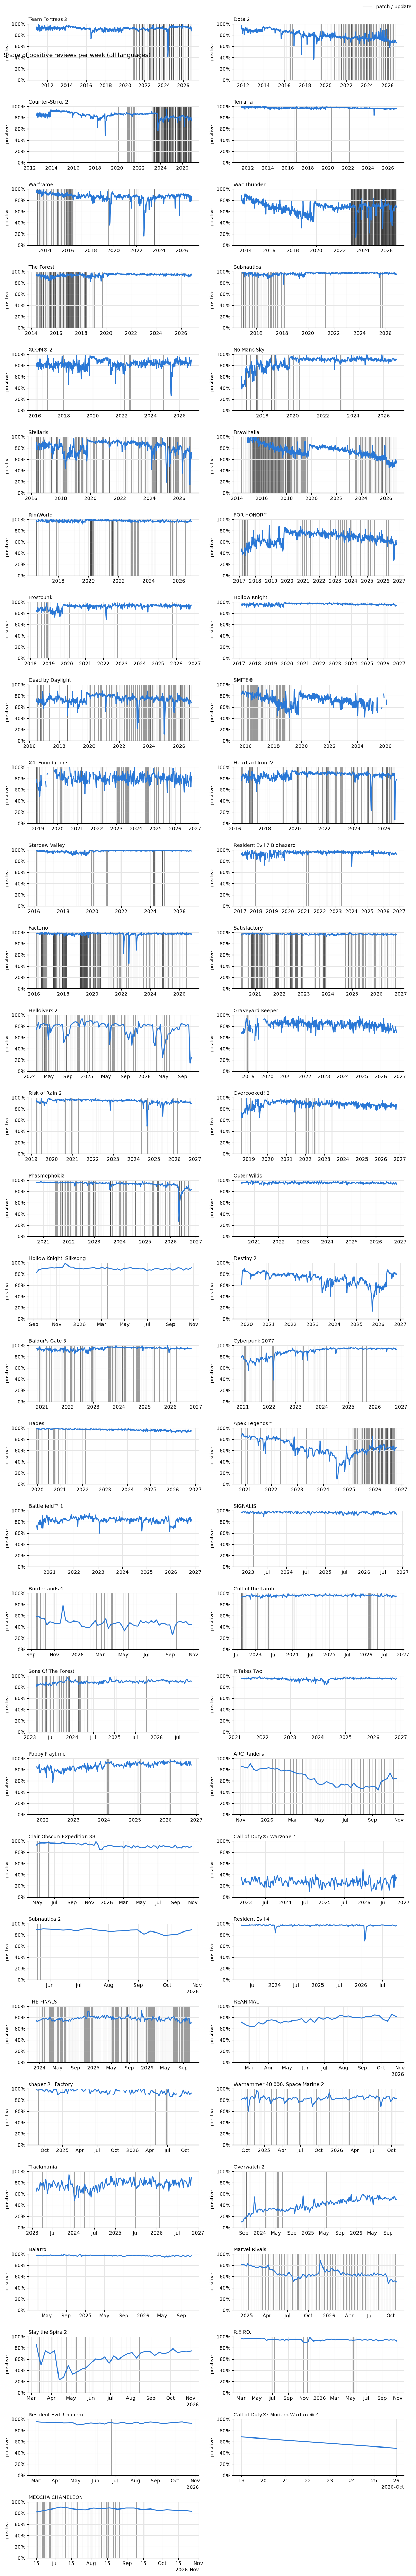

In [6]:
weeks = weekly(series)
per_game_panels(weeks["n"], "Kept reviews per week (all languages)", "reviews", patches=patches)
per_game_panels(weeks["positive"].where(weeks["n"] >= 20), "Share of positive reviews per week (all languages)",
                "positive", patches=patches, ylim=(0, 1), percent=True)

## 2. Trend and weekly seasonality

STL splits each daily series into a **trend**, a repeating **weekly** pattern and the **remainder**. It runs on log(1 + reviews), so the weekly pattern is a percentage, and on the 👍 share. Only games analysed per day are included, over the last `RECENT_DAYS` days and without their launch days.

Strength (0–1, Hyndman): trend = 1 − Var(remainder) / Var(trend + remainder), weekly likewise with the weekly part. Near 0 means the part explains little next to the noise.

In [7]:
def recent_part(appid, s=None):
    """A game's series (daily unless given) over the last RECENT_DAYS days, from LAUNCH_DAYS after its launch."""
    s = series.loc[appid] if s is None else s
    days = s.index
    return s[(days >= coverage.loc[appid, "launch"] + pd.Timedelta(days=LAUNCH_DAYS))
             & (days > days.max() - pd.Timedelta(days=RECENT_DAYS))]


def metrics(g):
    """The two series studied below: log(1 + reviews) and 👍 share (days without reviews filled from neighbours)."""
    return {"reviews (log)": np.log1p(g["n"]), "positive share": g["positive"].interpolate(limit_direction="both")}


too_new = [a for a in daily_games if len(recent_part(a)) < MIN_HISTORY]
studied = [a for a in daily_games if a not in too_new]
top_daily = [a for a in top_daily if a in studied]
print(f"too new for sections 2–4 (under {MIN_HISTORY} days after launch): {', '.join(names[a] for a in too_new) or 'none'}")

fits, rows = {}, []
for appid in studied:
    for metric, values in metrics(recent_part(appid)).items():
        fit = STL(values, period=7, robust=True).fit()
        fits[appid, metric] = fit
        remainder = fit.resid
        rows.append({"game": names[appid], "metric": metric,
                     "trend": max(0.0, 1 - remainder.var() / (fit.trend + remainder).var()),
                     "weekly": max(0.0, 1 - remainder.var() / (fit.seasonal + remainder).var())})
strength = pd.DataFrame(rows).pivot(index="game", columns="metric", values=["trend", "weekly"])
with pd.option_context("display.max_rows", 200):
    display(strength.sort_values(("trend", "reviews (log)"), ascending=False)
            .style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

too new for sections 2–4 (under 60 days after launch): Call of Duty®: Modern Warfare® 4, Dirt Clicker


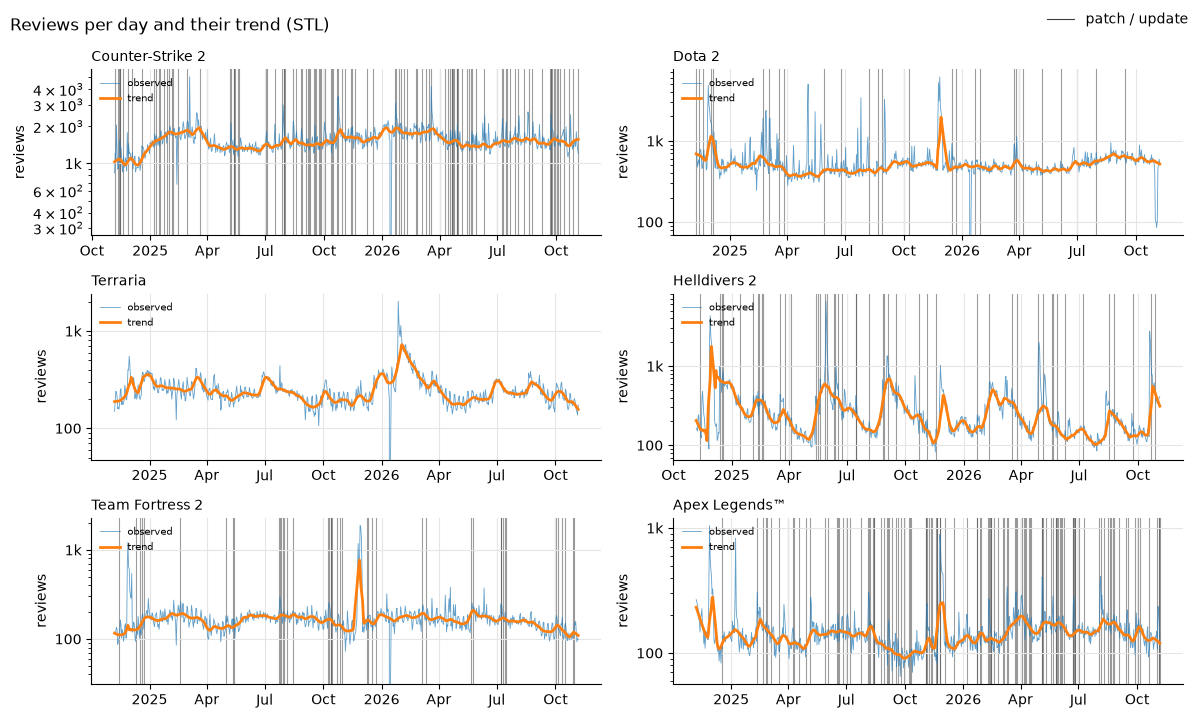

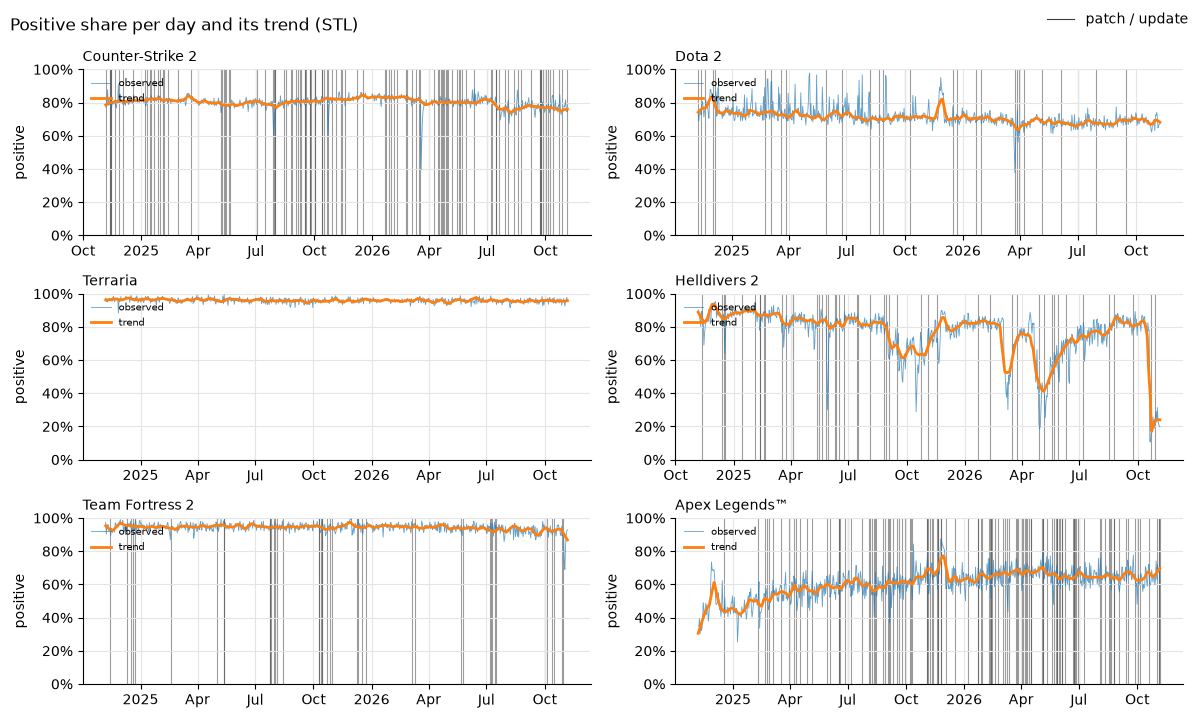

In [8]:
def stl_lines(metric, transform=lambda v: v):
    """(appid, day) frame: observed values and STL trend of the top games."""
    return pd.concat({appid: pd.DataFrame({"observed": transform(fits[appid, metric].observed),
                                           "trend": transform(fits[appid, metric].trend)})
                      for appid in top_daily}, names=["appid", "day"])


thin = {"observed": {"linewidth": 0.6, "alpha": 0.7}}
per_game_panels(stl_lines("reviews (log)", np.expm1), "Reviews per day and their trend (STL)", "reviews",
                patches=patches, log=True, styles=thin)
per_game_panels(stl_lines("positive share"), "Positive share per day and its trend (STL)", "positive",
                patches=patches, percent=True, ylim=(0, 1), styles=thin)

**Weekly pattern** per game: the STL weekly part averaged per weekday. Reviews are shown as % above or below the week's level, the 👍 share in percentage points.

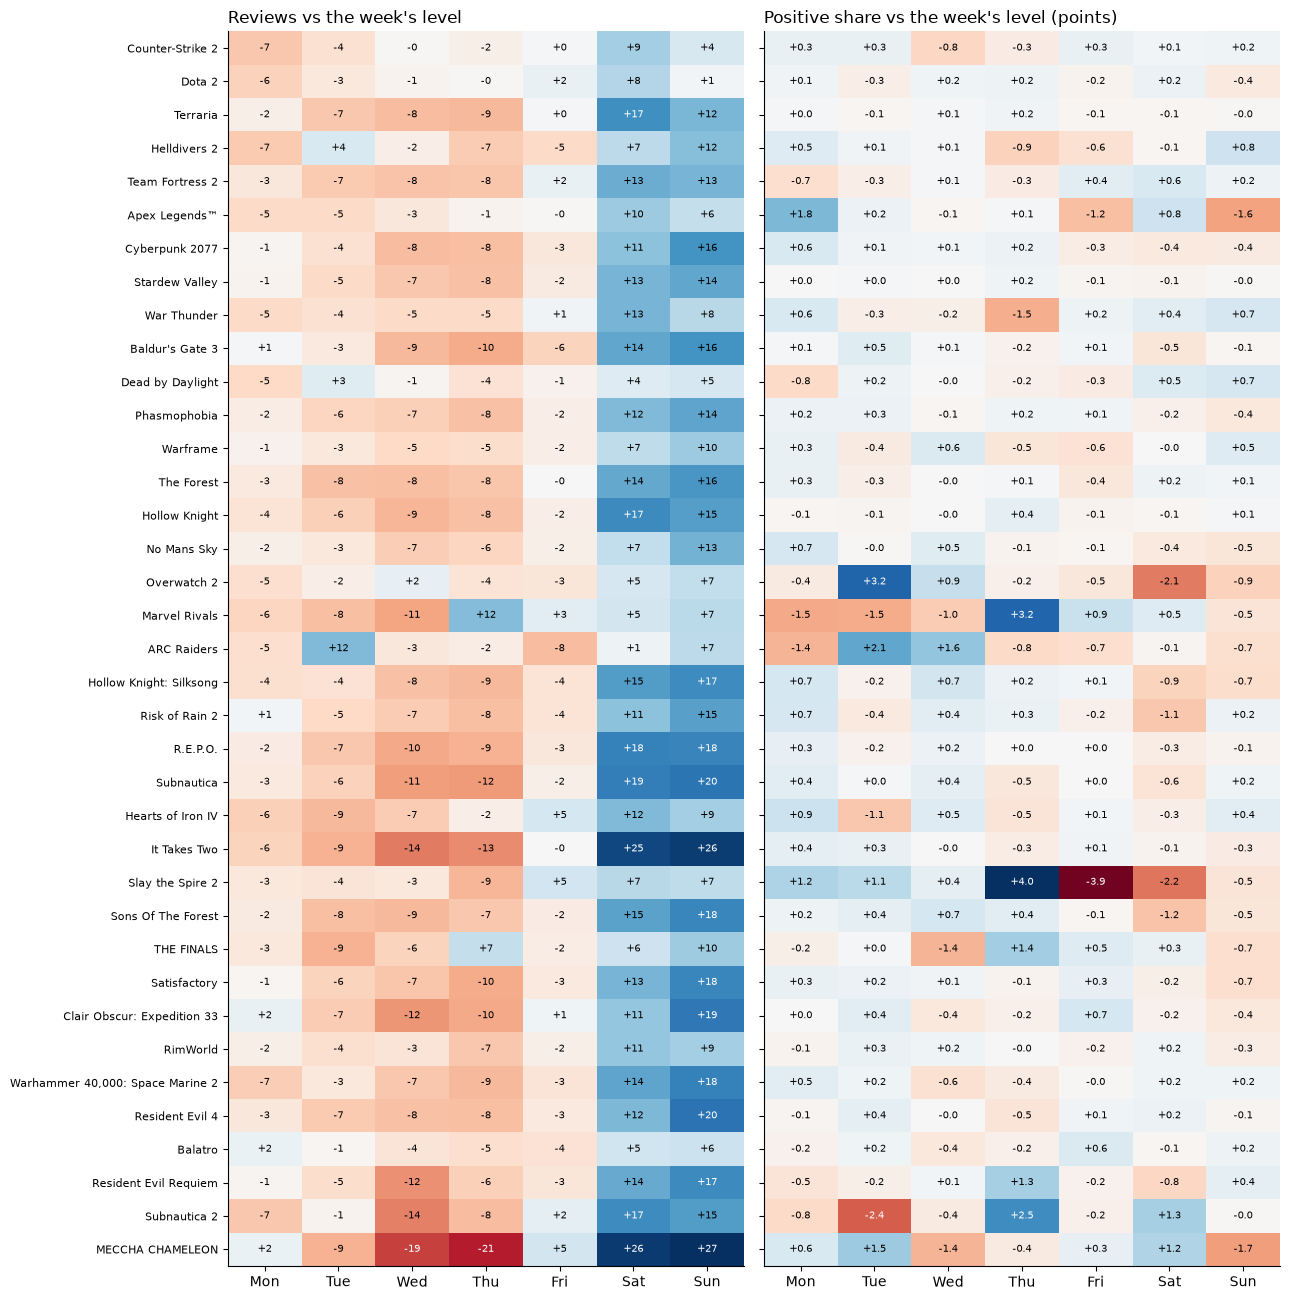

In [9]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
effects = {metric: pd.DataFrame({names[appid]: fit.seasonal.groupby(fit.seasonal.index.dayofweek).mean()
                                 for (appid, m), fit in fits.items() if m == metric}).T
           for metric in ["reviews (log)", "positive share"]}
effects["reviews (log)"] = np.expm1(effects["reviews (log)"])

fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(studied) + 2), sharey=True)
for ax, table, fmt, title in zip(
    axes, effects.values(), ["{:+.0%}", "{:+.1%}"],
    ["Reviews vs the week's level", "Positive share vs the week's level (points)"], strict=True,
):
    table = table.loc[effects["reviews (log)"].index]
    limit = np.abs(table.to_numpy()).max()
    ax.imshow(table, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    for (i, j), v in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, fmt.format(v).replace("%", ""), ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 * limit else "black")
    ax.set_xticks(range(7), WEEKDAYS)
    ax.set_yticks(range(len(table)), table.index, fontsize=8)
    ax.grid(False)
    ax.set_title(title, loc="left")
fig.tight_layout()

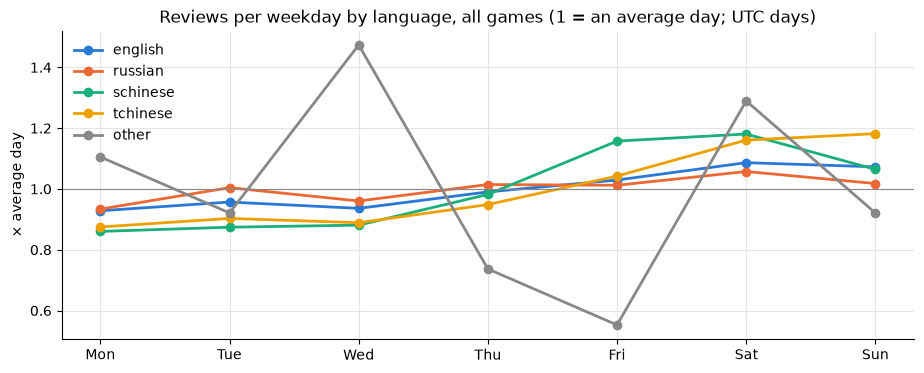

In [10]:
recent = series[series.index.get_level_values("day") > last_day - pd.Timedelta(days=RECENT_DAYS)]
lang_columns = [c for c in series.columns if c.startswith("n_") and c != "n_positive"]
by_weekday = recent[lang_columns].groupby(recent.index.get_level_values("day").dayofweek).sum()
by_weekday = by_weekday.loc[:, by_weekday.sum() > 0]
by_weekday = by_weekday / by_weekday.mean()  # 1 = an average day of that language

ax = plt.gca()
for column in by_weekday:
    language = column.removeprefix("n_")
    ax.plot(WEEKDAYS, by_weekday[column], marker="o", color=LANG_COLORS.get(language, "#888888"), label=language)
ax.axhline(1, color="#888888", linewidth=0.8)
ax.legend(frameon=False)
ax.set(title="Reviews per weekday by language, all games (1 = an average day; UTC days)", ylabel="× average day");

## 3. Stationarity

Two tests with opposite null hypotheses, per game, on the level and on the change from the previous day (or week):

- **ADF**: null = unit root (not stationary). p < 0.05 rejects it.
- **KPSS**: null = stationary. p < 0.05 rejects it.

Verdict: *stationary* (ADF rejects, KPSS does not), *unit root* (the opposite), *trend / mixed* (both reject: usually a trend or a shift in level), *unclear* (neither rejects).

For the models: a series that is stationary only after taking the change needs differencing (the d in ARIMA) or the change as the target.

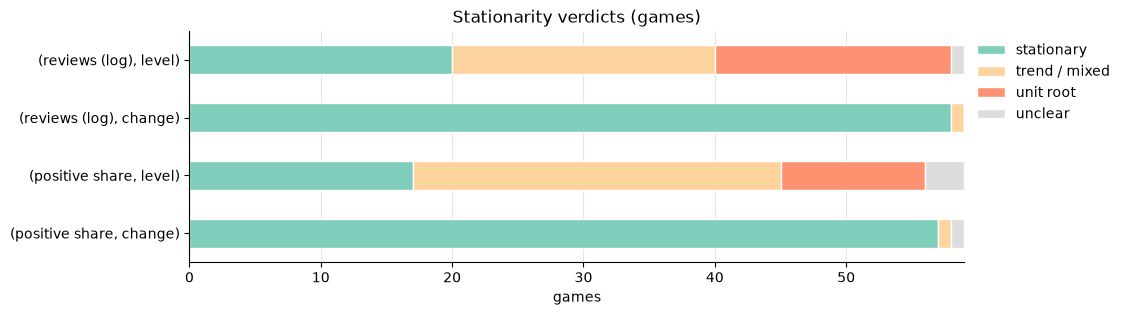

In [11]:
VERDICT_COLORS = {"stationary": "#7fcdbb", "trend / mixed": "#fdd49e", "unit root": "#fc9272", "unclear": "#dddddd"}


def verdict(adf_p, kpss_p, alpha=0.05):
    if adf_p < alpha:
        return "trend / mixed" if kpss_p < alpha else "stationary"
    return "unit root" if kpss_p < alpha else "unclear"


def game_series(appid):
    return recent_part(appid, series.loc[appid] if appid in daily_games else weekly_series.loc[appid])


rows = []
for appid in [a for a in coverage.index if a not in too_new]:
    for metric, values in metrics(game_series(appid)).items():
        for form, v in [("level", values), ("change", values.diff())]:
            v = v.dropna()
            if len(v) < 30 or v.nunique() < 3:
                continue
            adf_p = adfuller(v, autolag="AIC", result_object=True).pvalue
            kpss_p = kpss(v, regression="c", nlags="auto", result_object=True).pvalue
            rows.append({"game": names[appid], "per": coverage.loc[appid, "per"], "metric": metric,
                         "form": form, "ADF p": adf_p, "KPSS p": kpss_p, "verdict": verdict(adf_p, kpss_p)})
stationarity = pd.DataFrame(rows)

counts = (stationarity.groupby(["metric", "form"])["verdict"].value_counts().unstack(fill_value=0)
          .reindex(columns=list(VERDICT_COLORS), fill_value=0))
ax = counts.plot.barh(stacked=True, color=list(VERDICT_COLORS.values()), edgecolor="white", figsize=(10, 3))
ax.set(title="Stationarity verdicts (games)", xlabel="games", ylabel="")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left");

In [12]:
table = stationarity.pivot_table(index=["game", "per"], columns=["metric", "form"], values="verdict", aggfunc="first")
with pd.option_context("display.max_rows", 200):
    display(table.style.map(lambda v: f"background-color: {VERDICT_COLORS.get(v, '#ffffff')}"))

## 4. Autocorrelation

ACF: how much a day resembles the day `k` days earlier. PACF: the same with the days in between taken out, which hints at the AR order. Bars outside the shaded band are significant. Spikes at 7, 14, 21... mean a weekly pattern; a slow decay means a trend or long memory (see section 3).

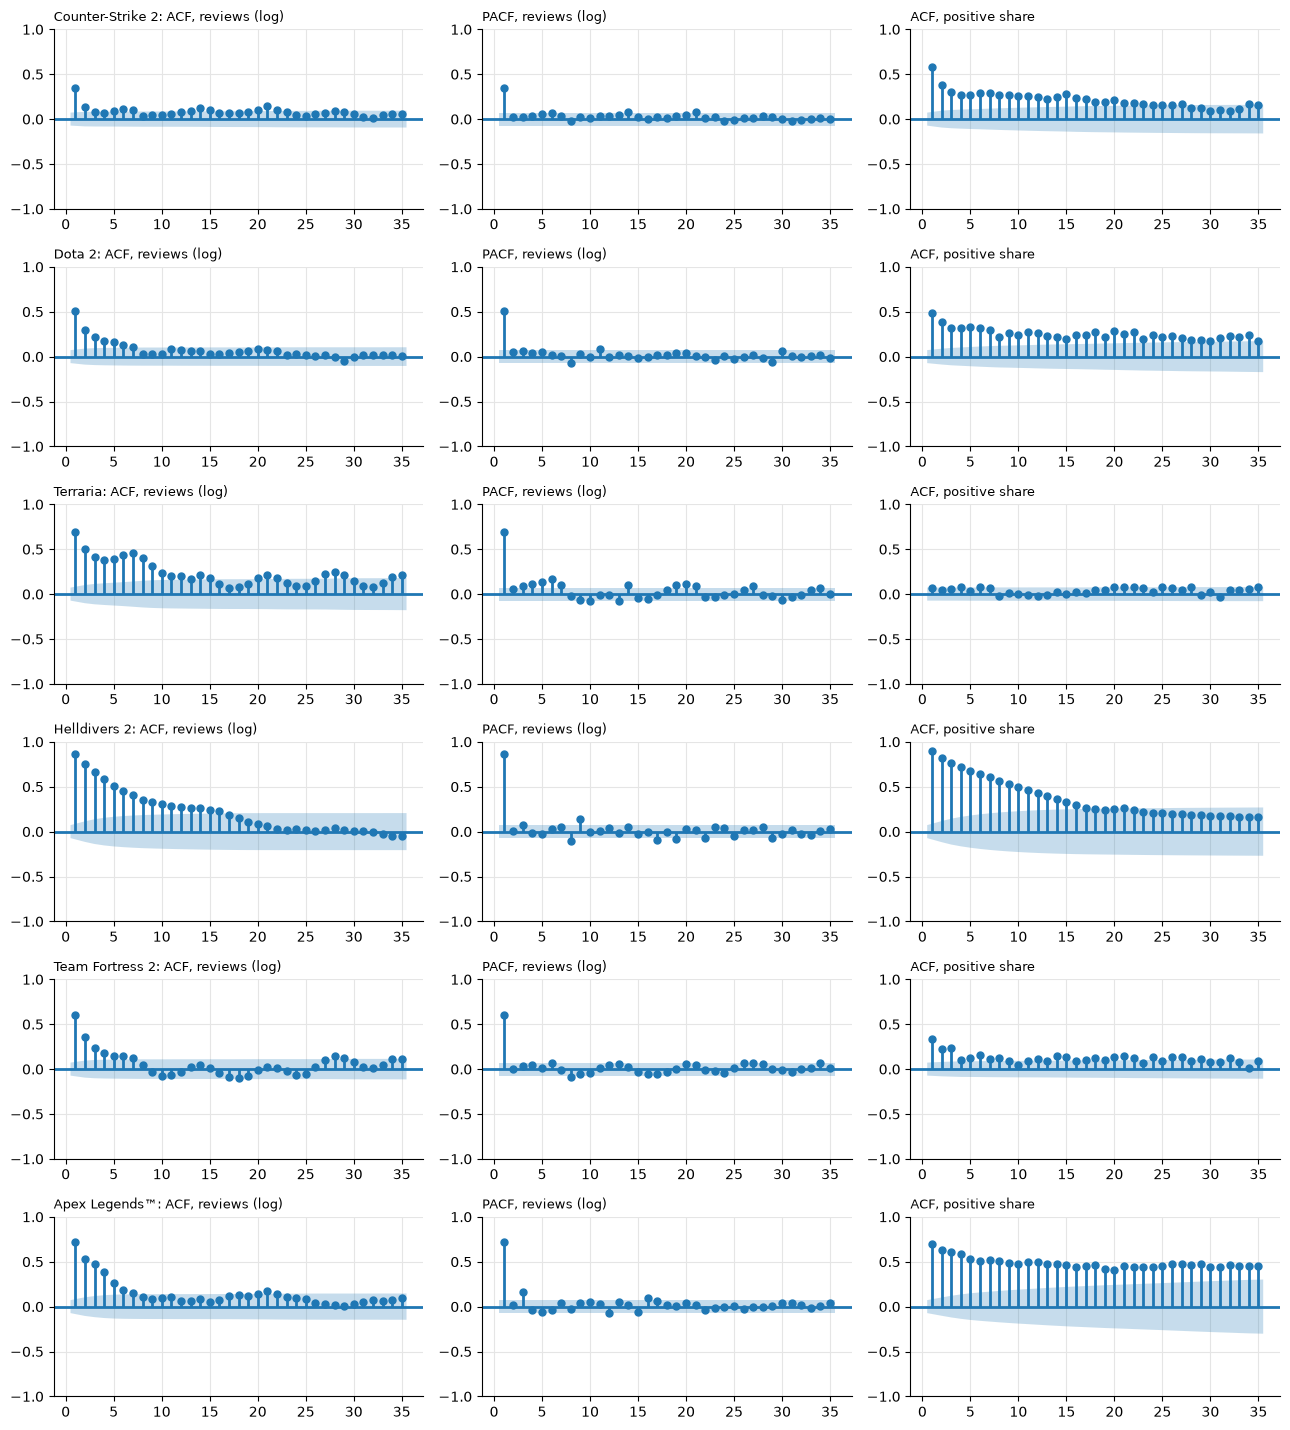

In [13]:
fig, axes = plt.subplots(len(top_daily), 3, figsize=(13, 2.4 * len(top_daily)), squeeze=False)
for row, appid in zip(axes, top_daily, strict=True):
    m = metrics(recent_part(appid))
    plot_acf(m["reviews (log)"], lags=35, ax=row[0], title=f"{names[appid]}: ACF, reviews (log)", zero=False)
    plot_pacf(m["reviews (log)"], lags=35, ax=row[1], title="PACF, reviews (log)", zero=False, method="ywm")
    plot_acf(m["positive share"], lags=35, ax=row[2], title="ACF, positive share", zero=False)
    for ax in row:
        ax.title.set(fontsize=9, ha="left", x=0)
fig.tight_layout()

In [14]:
LAGS = [1, 7, 14, 28]
rows = {}
for appid in studied:
    for metric, values in metrics(recent_part(appid)).items():
        rows[names[appid], metric] = acf(values, nlags=max(LAGS))[LAGS]
lag_table = pd.DataFrame(rows, index=[f"lag {k}" for k in LAGS]).T.unstack(level=1)
lag_table = lag_table.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
print("Autocorrelation at chosen lags (games analysed per day)")
with pd.option_context("display.max_rows", 200):
    display(lag_table.style.format("{:.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1))

Autocorrelation at chosen lags (games analysed per day)


## 5. Anomalies: spikes and review bombing

- **count**: log(1 + reviews) against the median of the window, in robust standard deviations;
- **👎 share**: against the window's 👎 share, in binomial standard errors, so a day with few reviews needs a bigger jump;
- only days with at least 20 reviews and enough history count, and not a game's launch.

Kinds: **bombing**: both jump (many reviews, mostly negative); **negative**: the 👎 share jumps without many more reviews; **spike**: many more reviews with the usual 👎 share (launches, updates, sales, free weekends). Consecutive unusual days of a game form one **event**.

In [15]:
daily_part = games_in(series, daily_games)
found = pd.concat([
    review_anomalies(daily_part, window=ANOMALY_WINDOW, z=ANOMALY_Z,
                     exclude=launch_window(daily_part.index, coverage["first_review"], LAUNCH_DAYS)).assign(per="day"),
    review_anomalies(weekly_series, window=ANOMALY_WEEKS, z=ANOMALY_Z,
                     exclude=launch_window(weekly_series.index, coverage["first_review"], LAUNCH_DAYS)).assign(per="week"),
])
events = pd.concat([group_events(found[found["per"] == per], step_days).assign(per=per)
                    for per, step_days in [("day", 1), ("week", 7)]], ignore_index=True)
events["game"] = events["appid"].map(names)
print(f"{found['kind'].notna().sum():,} unusual days or weeks in {len(events):,} events: "
      + ", ".join(f"{n} {kind}" for kind, n in events["kind"].value_counts().items()))

4,143 unusual days or weeks in 1,330 events: 613 negative, 594 spike, 123 bombing


**Steam-wide events**: days when many games get unusually many reviews at once.

194 Steam-wide event days in 46 periods; 42% of spike events overlap one


start,last,days,most_games_rising,peak_share
2013-11-25,2013-12-02,8,6,100%
2016-11-23,2016-11-29,7,13,100%
2017-11-22,2017-11-28,7,14,100%
2019-10-25,2019-11-06,13,15,100%
2019-06-26,2019-07-06,11,15,100%
2018-11-21,2018-11-27,7,14,100%
2020-11-25,2020-12-01,7,18,95%
2022-11-22,2022-11-28,7,19,90%
2021-11-24,2021-11-30,7,19,90%
2023-11-21,2023-11-28,8,21,88%


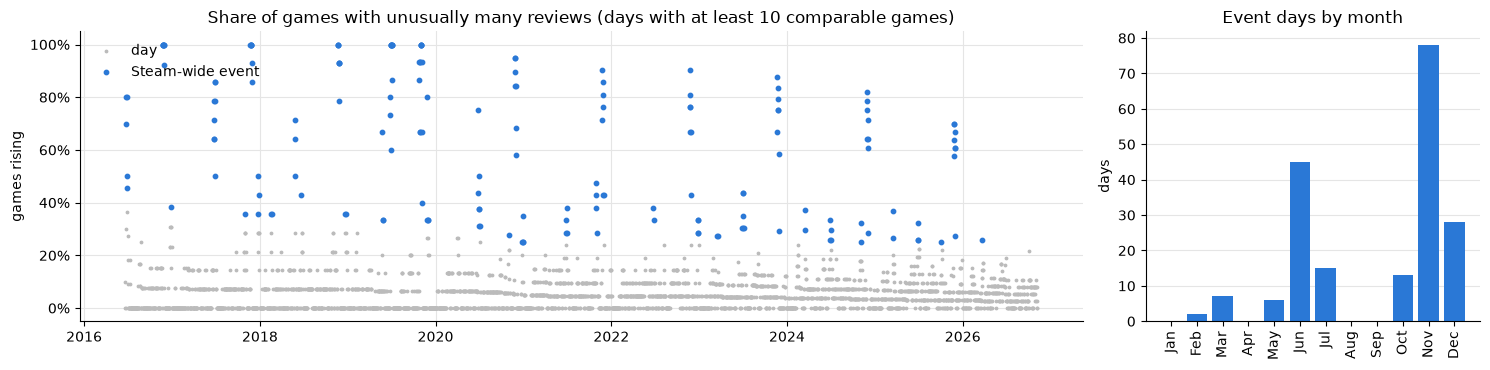

In [16]:
platform = platform_days(found[found["per"] == "day"])
platform.to_parquet(FEATURES_DIR / "platform_days.parquet")
hot_days = platform.index[platform["platform"]]
periods = pd.DataFrame({"day": hot_days})
periods["period"] = (periods["day"].diff() > pd.Timedelta(days=2)).cumsum()
periods = periods.join(platform[["rising", "share"]], on="day").groupby("period").agg(
    start=("day", "min"), last=("day", "max"), days=("day", "size"),
    most_games_rising=("rising", "max"), peak_share=("share", "max"))
event_days = {e: set(pd.date_range(r.start, r.last)) for e, r in events.iterrows()}
events["steam_wide"] = [bool(days & set(hot_days)) for days in event_days.values()]
print(f"{len(hot_days)} Steam-wide event days in {len(periods)} periods; "
      f"{events.loc[events['kind'] == 'spike', 'steam_wide'].mean():.0%} of spike events overlap one")

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [3, 1]})
shown = platform[platform["games"] >= 10]
axes[0].scatter(shown.index, shown["share"], s=3, color="#bbbbbb", label="day")
axes[0].scatter(shown.index[shown["platform"]], shown.loc[shown["platform"], "share"], s=10, color="#2a78d6",
                label="Steam-wide event")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set(title="Share of games with unusually many reviews (days with at least 10 comparable games)",
            ylabel="games rising")
date_axis(axes[0])
axes[0].legend(frameon=False, loc="upper left")
by_month = pd.Series(hot_days.month).value_counts().reindex(range(1, 13), fill_value=0)
axes[1].bar(range(1, 13), by_month, color="#2a78d6")
axes[1].set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
                   rotation=90)
axes[1].set(title="Event days by month", ylabel="days")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
display(periods.sort_values("peak_share", ascending=False).head(TOP_EVENTS).style.format({
    "start": "{:%Y-%m-%d}", "last": "{:%Y-%m-%d}", "peak_share": "{:.0%}"}).hide(axis="index"))

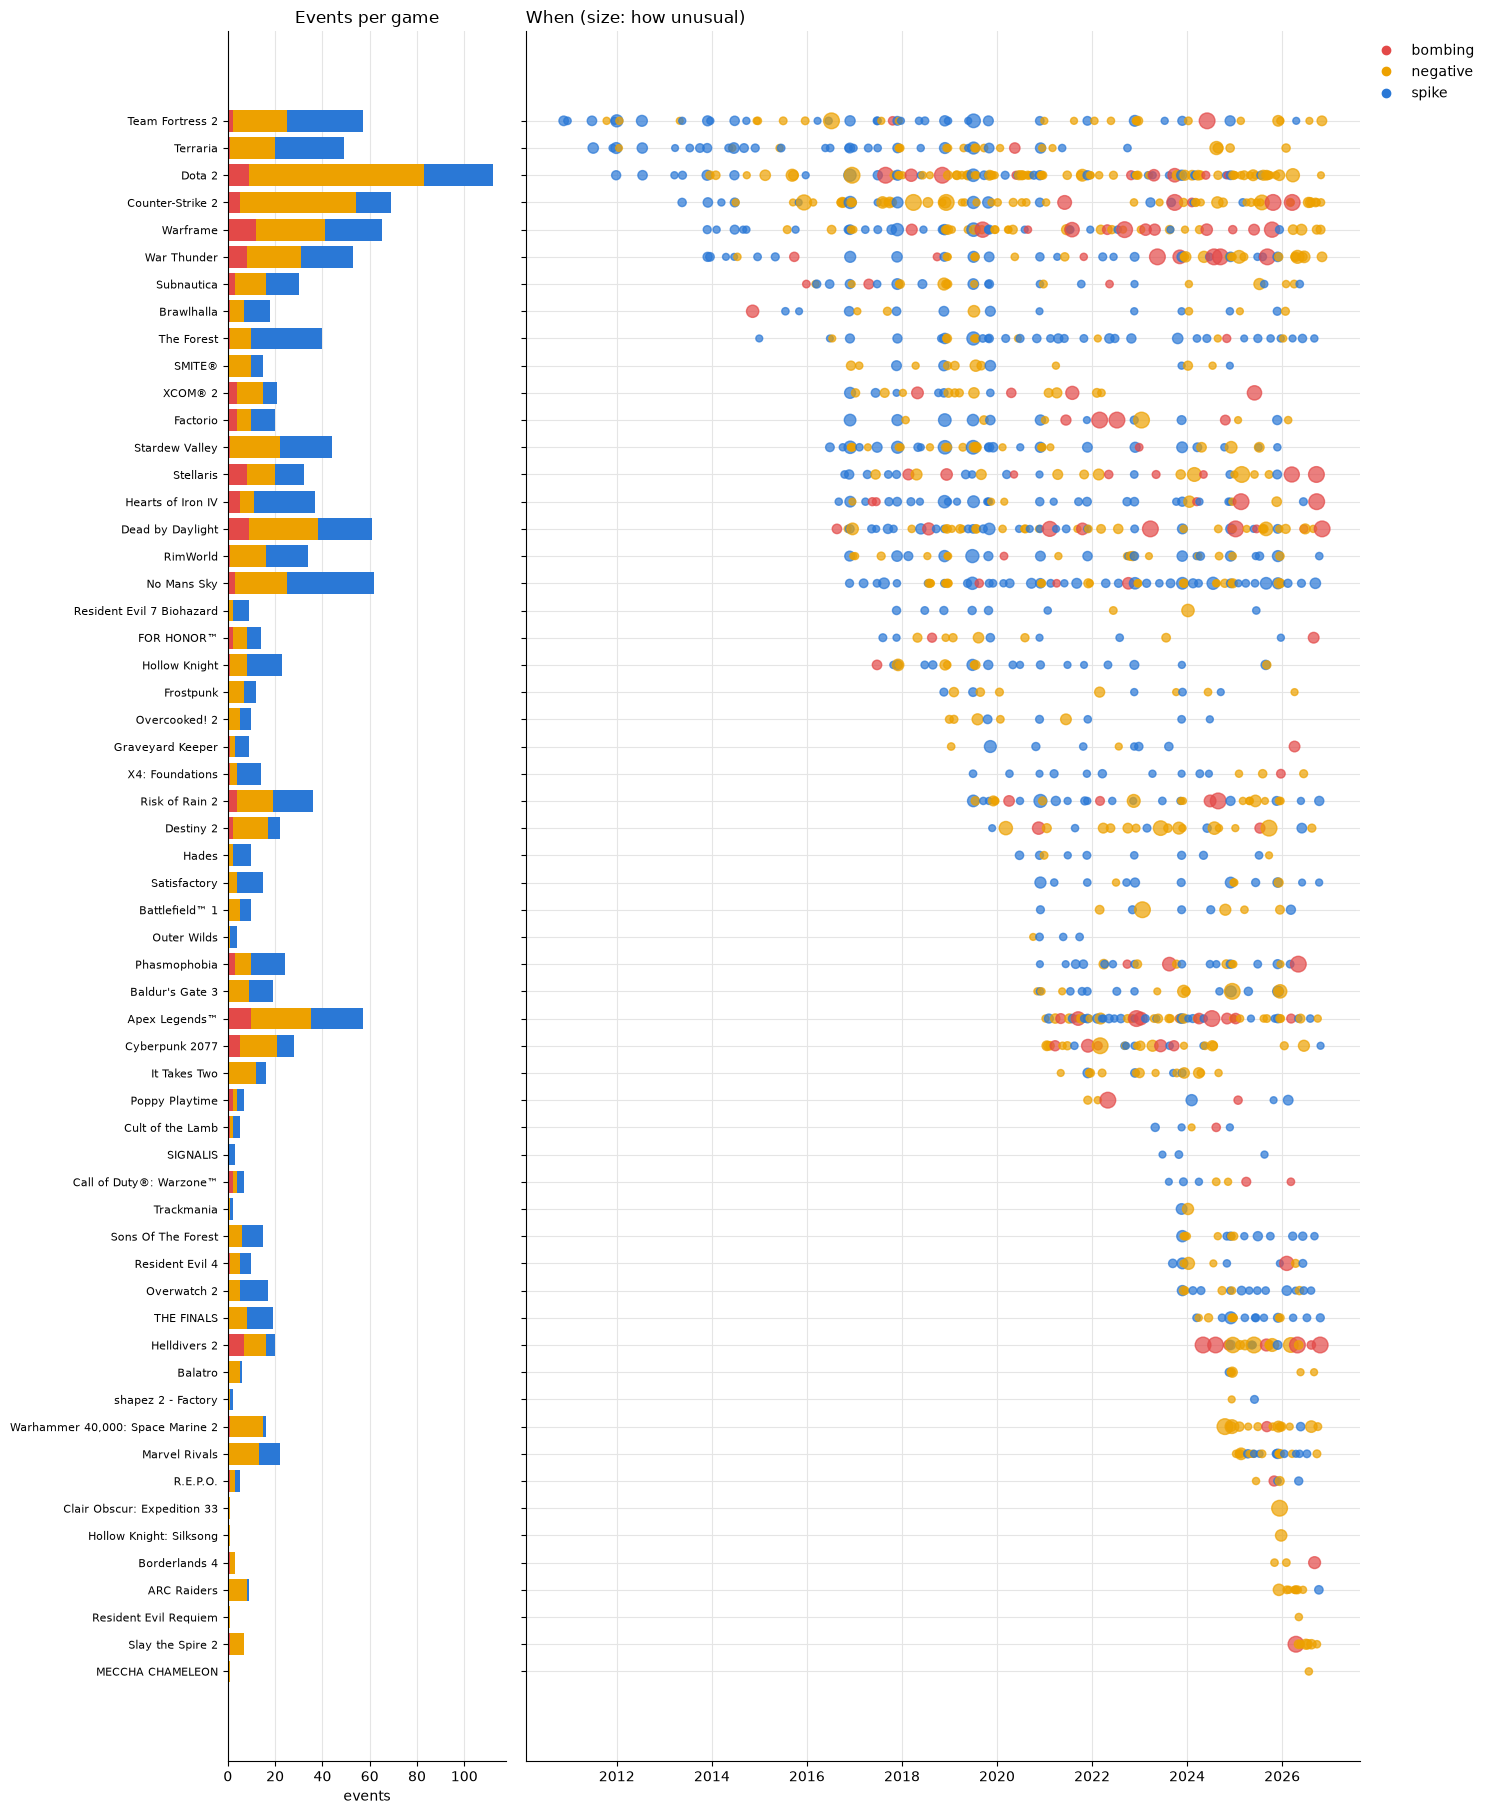

In [17]:
order = coverage.sort_values("first_review").index
per_game = events.groupby(["appid", "kind"]).size().unstack(fill_value=0).reindex(columns=KINDS, fill_value=0)
per_game = per_game.reindex(order).dropna().iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 0.27 * len(order) + 1.5), gridspec_kw={"width_ratios": [1, 3]}, sharey=True)
left = np.zeros(len(per_game))
position = {appid: i for i, appid in enumerate(per_game.index)}
for kind in KINDS:
    axes[0].barh(range(len(per_game)), per_game[kind], left=left, color=KIND_COLORS[kind], label=kind)
    left += per_game[kind].to_numpy()
axes[0].set_yticks(range(len(per_game)), per_game.index.map(names), fontsize=8)
axes[0].set(title="Events per game", xlabel="events")
axes[0].grid(axis="y", visible=False)
shown = events[events["appid"].isin(per_game.index)]
axes[1].scatter(shown["peak"], shown["appid"].map(position), c=shown["kind"].map(KIND_COLORS),
                s=8 + 4 * shown[["z_count", "z_negative"]].max(axis=1).clip(upper=30), alpha=0.7)
date_axis(axes[1])
axes[1].set_title("When (size: how unusual)", loc="left")
axes[1].legend(handles=[Line2D([], [], marker="o", linestyle="", color=KIND_COLORS[k], label=k) for k in KINDS],
               frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()

**Patches**: how many events start on a patch day or up to 3 days after one, compared with how many of all days are that close after a patch (games analysed per day). Much higher than the base rate means patches often cause the unusual days.

In [18]:
patch_flag = series["patch"].astype(int)
after_patch = patch_flag.groupby(level="appid").transform(lambda s: s.rolling(4, min_periods=1).max()).astype(bool)
daily_events = events[events["per"] == "day"]
starts_after_patch = after_patch.reindex(pd.MultiIndex.from_arrays([daily_events["appid"], daily_events["start"]])).to_numpy()
summary = daily_events.assign(after_patch=starts_after_patch).groupby("kind")["after_patch"].agg(events="size", share_after_patch="mean")
summary.loc["all days (base rate)"] = [games_in(after_patch, daily_games).size, games_in(after_patch, daily_games).mean()]
summary.style.format({"events": "{:,.0f}", "share_after_patch": "{:.0%}"})

,events,share_after_patch
kind,,
bombing,94,31%
negative,511,21%
spike,476,19%
all days (base rate),"91,176",10%


**Biggest events**. For each: what changed in the topics and languages (of the text, as detected) of that game's reviews compared with the 28 days before (percentage points of all its reviews), and the nearest patch or news item (from 3 days before to the end).

In [19]:
def share_jump(counts, start, end, top):
    """Columns whose share of the row sums grew most in [start, end) vs the 28 days before, in points."""
    during = counts.loc[start : end - pd.Timedelta(days=1)].sum()
    before = counts.loc[start - pd.Timedelta(days=28) : start - pd.Timedelta(days=1)].sum()
    if during.sum() == 0 or before.sum() == 0:
        return pd.Series(dtype=float)
    jump = (during / during.sum() - before / before.sum()).nlargest(top)
    return jump[jump > 0]


topic_games = set(topic_counts.index.get_level_values("appid"))


def topics_up(e, top=3):
    if e.appid not in topic_games:
        return ""
    counts = topic_counts.loc[e.appid].drop(columns=[TOPIC_SHORT, TOPIC_NOISE], errors="ignore")
    return "; ".join(f"{textwrap.shorten(topic_labels.get(t, str(t)), 45)} {v:+.0%}"
                     for t, v in share_jump(counts, e.start, e.end, top).items())


text_columns = [c for c in series.columns if c.startswith("text_")]


def languages_up(e):
    """By the detected language of the text: a Turkish campaign in the English section shows as "other"."""
    return "; ".join(f"{c.removeprefix('text_')} {v:+.0%}" for c, v in share_jump(series.loc[e.appid, text_columns], e.start, e.end, 2).items())


def nearest_news(e):
    near = news[(news["appid"] == e.appid) & news["day"].between(e.start - pd.Timedelta(days=3), e.end)]
    if near.empty:
        return ""
    first = near.sort_values(["is_patch", "day"], ascending=[False, True]).iloc[0]
    return f"{first['day']:%m-%d} {'patch' if first['is_patch'] else 'news'}: {textwrap.shorten(str(first['title']), 60)}"


def event_table(rows):
    rows = rows.assign(topics_up=[topics_up(e) for e in rows.itertuples()],
                       languages_up=[languages_up(e) for e in rows.itertuples()],
                       news=[nearest_news(e) for e in rows.itertuples()])
    columns = ["game", "kind", "per", "start", "last", "reviews", "usual_reviews", "negative", "usual_negative",
               "topics_up", "languages_up", "news"]
    return rows[columns].style.format({
        "start": "{:%Y-%m-%d}", "last": "{:%Y-%m-%d}", "reviews": "{:,.0f}", "usual_reviews": "{:,.0f}",
        "negative": "{:.0%}", "usual_negative": "{:.0%}",
    }).hide(axis="index")


negative_events = events[events["kind"].isin(["bombing", "negative"])].nlargest(TOP_EVENTS, "z_negative")
print("Biggest jumps in the 👎 share (bombing, negative)")
display(event_table(negative_events))
print("Biggest review spikes with the usual 👎 share, outside Steam-wide events")
display(event_table(events[(events["kind"] == "spike") & ~events["steam_wide"]].nlargest(TOP_EVENTS, "z_count")))

Biggest jumps in the 👎 share (bombing, negative)


game,kind,per,start,last,reviews,usual_reviews,negative,usual_negative,topics_up,languages_up,news
Hearts of Iron IV,bombing,day,2026-09-22,2026-09-29,"14,555",62,94%,14%,44 · Politics +13%; 34 · Price and DLC +12%; 21 · Insults and profanity +8%,en +31%; other +11%,09-22 news: HOI IV Dev Corner | The Great Depression
Factorio,bombing,week,2022-07-11,2022-07-11,"1,723",298,56%,2%,28 · Price and DLC +23%; 36 · Price and DLC +14%; 44 · Politics +10%,ru +54%; other +0%,
Helldivers 2,bombing,day,2024-04-29,2024-05-11,"344,805","1,738",34%,16%,"31 · Launchers, accounts and anti-cheat +34%; 69 · Refunds and regret +1%; 25 · Negative review until fixed +1%",zh +4%,04-29 patch: Patch 01.000.300
Counter-Strike 2,negative,day,2018-12-06,2018-12-16,"29,784",628,53%,14%,33 · Free to play +15%; 69 · Refunds and regret +7%; 36 · Price and DLC +4%,en +9%; zh +0%,12-06 news: CS:GO goes Battle Royale and free to play
Counter-Strike 2,bombing,day,2023-09-27,2023-10-15,"83,756","1,747",43%,13%,"6 · Crashes, bugs and performance +4%; 66 · Updates made it worse +3%; 21 · Insults and profanity +3%",zh +2%; en +0%,09-27 patch: Release Notes for 9/27/2023
Helldivers 2,negative,day,2025-05-28,2025-05-30,"11,368",279,62%,17%,25 · Negative review until fixed +14%; 0 · General opinions (Chinese) +6%; 20 · Insults and profanity +5%,zh +55%; other +0%,05-27 patch: Patch 01.003.003
Factorio,bombing,week,2022-02-28,2022-03-07,"1,939",328,37%,2%,44 · Politics +31%; 57 · Great graphics and story +1%; 77 · Trash game +1%,zh +15%; ru +4%,"02-25 news: Friday Facts #368 - Steam deck, Ghost bugs, Docs [...]"
Helldivers 2,bombing,day,2026-10-20,2026-10-27,"9,315",144,85%,19%,"63 · Launchers, accounts and anti-cheat +9%; 11 · Won't launch or log in +5%; 66 · Updates made it worse +5%",zh +9%,10-22 patch: Devoid of Liberty: 7.2.1
Warframe,bombing,day,2022-09-07,2022-09-14,"11,417",85,83%,17%,0 · General opinions (Chinese) +20%; 20 · Insults and profanity +7%; 25 · Negative review until fixed +5%,zh +50%,09-07 news: Available Now: Veilbreaker
Dead by Daylight,bombing,day,2025-01-07,2025-01-14,"7,776",95,88%,26%,"12 · Cheaters, bots and bans +12%; 63 · Launchers, accounts and anti-cheat +12%; 25 · Negative review until fixed +7%",zh +65%,01-08 patch: 8.5.0 | PTB Patch Notes


Biggest review spikes with the usual 👎 share, outside Steam-wide events


game,kind,per,start,last,reviews,usual_reviews,negative,usual_negative,topics_up,languages_up,news
No Mans Sky,spike,day,2024-07-17,2024-07-23,"4,197",38,5%,8%,7 · Strong recommendation +8%; 40 · Sequel vs the original +4%; 9 · Best game I've played +3%,en +16%; other +0%,07-17 news: No Man's Sky's Worlds Update part one comes with a [...]
Team Fortress 2,spike,day,2011-12-27,2012-01-01,"2,050",26,5%,9%,21 · Insults and profanity +2%; 13 · Fun with friends +1%; 5 · Short praise +1%,ru +1%; other +0%,
No Mans Sky,spike,day,2025-08-27,2025-09-03,"4,420",36,7%,10%,4 · Short praise +3%; 9 · Best game I've played +2%; 27 · Waiting for updates and content +2%,en +5%; zh +1%,08-27 news: No Man's Sky's Voyagers update adds in big custom [...]
Poppy Playtime,spike,week,2024-01-29,2024-02-12,"4,611",96,8%,11%,57 · Great graphics and story +2%; 1 · General opinions (Russian) +1%; 0 · General opinions (Chinese) +1%,ru +1%,"02-01 patch: Small Patch Update Feb 01, 2024"
Team Fortress 2,spike,day,2012-07-12,2012-07-18,"1,944",30,7%,9%,33 · Free to play +6%; 30 · 'Simulator' jokes +3%; 4 · Short praise +1%,ru +2%,
Terraria,spike,day,2011-12-27,2012-01-02,"1,867",25,1%,1%,4 · Short praise +3%; 7 · Strong recommendation +2%; 13 · Fun with friends +1%,en +1%,12-29 news: The ‘Complete’ A Smurf In Terraria
Trackmania,spike,week,2023-11-20,2023-11-20,"1,576",64,6%,28%,4 · Short praise +6%; 13 · Fun with friends +4%; 9 · Best game I've played +4%,ru +6%; other +0%,11-21 news: CELEBRATE TRACKMANIA’S 20TH ANNIVERSARY TODAY WITH NEW [...]
No Mans Sky,spike,day,2017-08-11,2017-08-17,"2,519",11,11%,33%,"7 · Strong recommendation +11%; 40 · Sequel vs the original +6%; 6 · Crashes, bugs and performance +3%",zh +4%; ru +1%,08-08 patch: No Man's Sky teases portals and spacecrafts ahead of [...]
Terraria,spike,day,2011-07-03,2011-07-05,556,18,0%,1%,47 · Comparisons with other games +3%; 17 · Genre praise +2%; 33 · Free to play +1%,ru +1%,
No Mans Sky,spike,day,2026-09-09,2026-09-15,"2,371",46,8%,8%,27 · Waiting for updates and content +1%; 33 · Free to play +1%; 36 · Price and DLC +1%,en +4%,09-09 news: A complete overhaul to space arrives in the form of No [...]


**Close-ups** of the biggest 👎 events: reviews per day (👍 / 👎) 45 days before and after, and the daily share (7-day mean) of the topics that grew most. The shaded span is the event.

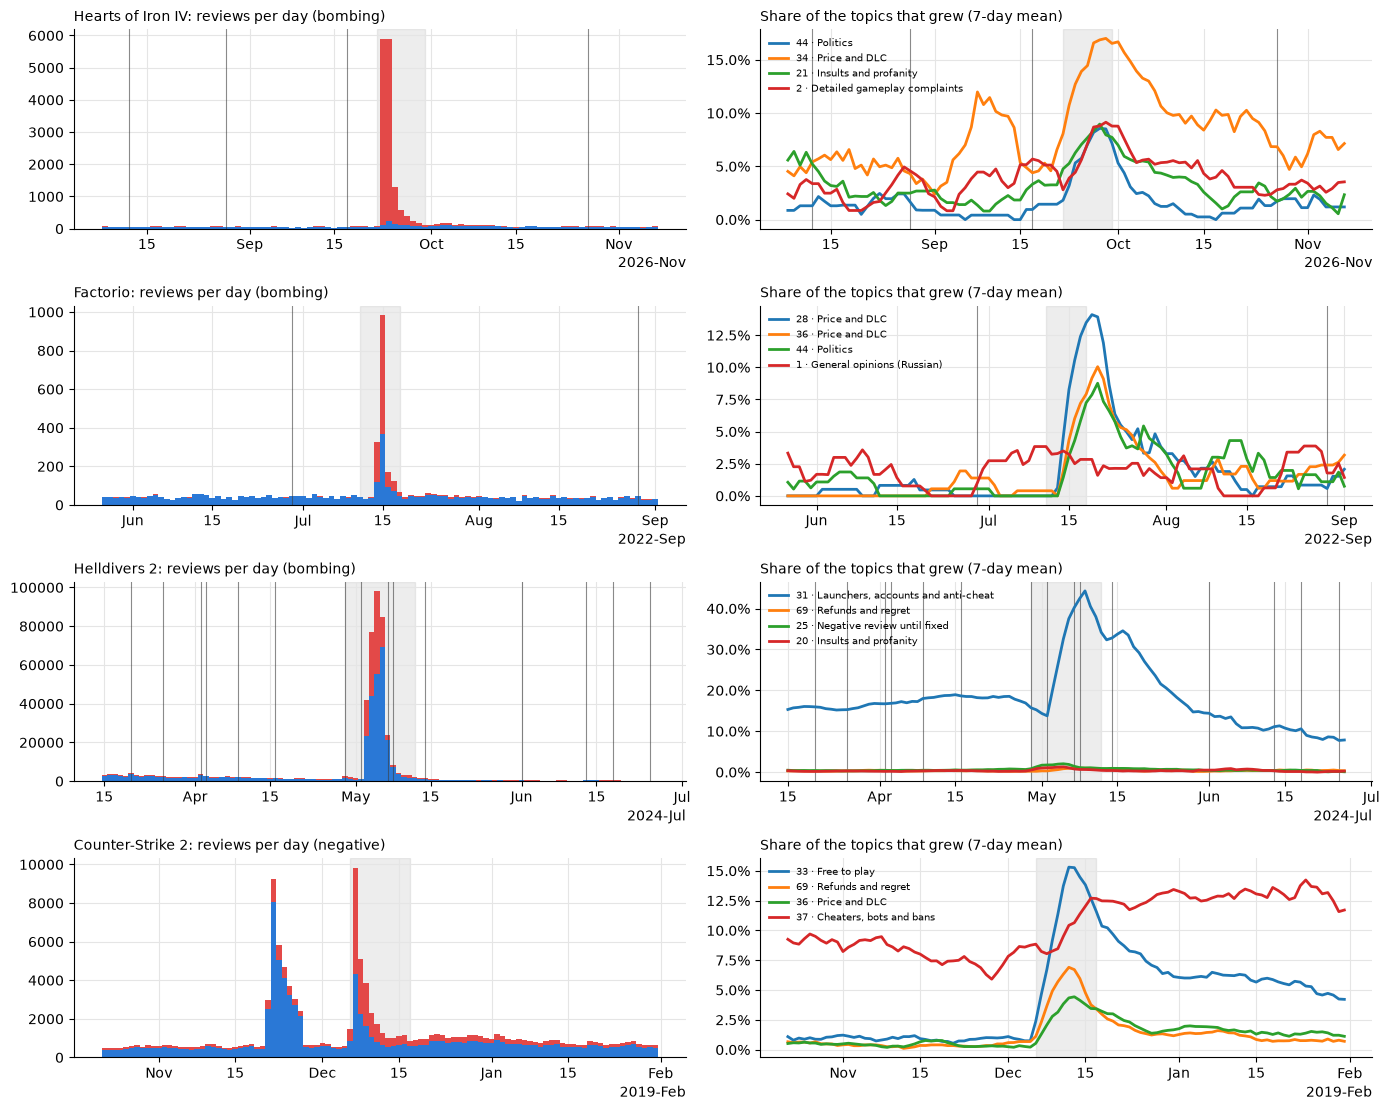

In [20]:
CLOSE_UPS = 4
fig, axes = plt.subplots(min(CLOSE_UPS, len(negative_events)), 2, figsize=(14, 2.8 * CLOSE_UPS), squeeze=False)
for row, e in zip(axes, negative_events.head(CLOSE_UPS).itertuples(), strict=False):
    window = slice(e.start - pd.Timedelta(days=45), e.end + pd.Timedelta(days=45))
    days = series.loc[e.appid].loc[window]
    row[0].bar(days.index, days["n_positive"], width=1, color="#2a78d6", label="👍")
    row[0].bar(days.index, days["n"] - days["n_positive"], bottom=days["n_positive"], width=1, color="#e34948", label="👎")
    row[0].set_title(f"{e.game}: reviews per day ({e.kind})", loc="left", fontsize=10)
    for ax in row:
        ax.axvspan(e.start, e.end, color="#888888", alpha=0.15, zorder=0)
        for day in patches[patches.get_level_values(0) == e.appid].get_level_values(1):
            if window.start <= day <= window.stop:
                ax.axvline(day, color=PATCH_COLOR, linewidth=0.8, alpha=0.6)
        date_axis(ax)
    if e.appid in topic_games:
        counts = topic_counts.loc[e.appid].drop(columns=[TOPIC_SHORT, TOPIC_NOISE], errors="ignore")
        shares = counts.div(counts.sum(axis=1).where(lambda s: s > 0), axis=0).rolling(7, min_periods=1).mean().loc[window]
        for t in share_jump(counts, e.start, e.end, 4).index:
            row[1].plot(shares.index, shares[t], label=textwrap.shorten(topic_labels.get(t, str(t)), 40))
        row[1].yaxis.set_major_formatter(PercentFormatter(1.0))
        row[1].legend(fontsize=7, frameon=False, loc="upper left")
    row[1].set_title("Share of the topics that grew (7-day mean)", loc="left", fontsize=10)
fig.tight_layout()

**What people wrote**: negative reviews from the peak day (or week) of the biggest 👎 events.

In [21]:
for e in negative_events.head(3).itertuples():
    texts = read.reviews(appids=[e.appid], since=e.peak, until=e.peak + e.step, only_kept=True, flag_columns=[],
                         columns=["voted_up", "language", "review"])
    negative = texts[~texts["voted_up"].astype(bool)]
    print(f"\n=== {e.game}, {e.peak:%Y-%m-%d} ({e.per}): {len(texts):,} reviews, {len(negative) / max(len(texts), 1):.0%} negative")
    for r in negative.sample(min(6, len(negative)), random_state=0).itertuples():
        print(f"- [{r.language}] {textwrap.shorten(' '.join(r.review.split()), 220)}")


=== Hearts of Iron IV, 2026-09-23 (day): 5,888 reviews, 98% negative
- [english] sikerler demedik mi şaşkın
- [english] Oçtur piçtir
- [english] Paradox has quite a monopoly in this industry. They always sell core features as DLCs, and their community management is terrible.
- [english] çöp
- [english] VERY BAD GAME!!!
- [english] its too hard to play and also game is nearly half when you play vanilla version. Why do i need to pay for dlc's? the vanilla version is already expensive.

=== Factorio, 2022-07-11 (week): 1,723 reviews, 56% negative
- [russian] Игра классная, жаль перепродать за 5к не успел, пока мог(
- [russian] И что вы хотите этим показать? Сделав игру за 10 тысяч рублей. Кроме ненависти игроков - вы ничего не добьётесь
- [english] Silly dev supporting nazis.
- [russian] Положительный отзыв не доступен в вашем регионе. 10к рублей из 10.
- [english] Положительный отзыв недоступен в вашем регионе.
- [russian] Мне до феньки великие планы Европы с Великой Польшей, где «солид